# Subtrace-Conditional Validation, No-Noise Generalization: Four Cases, Zero Measurement Noise

This notebook generalizes **Section 9** of
`NRL_logic_and_input_error_experiment.ipynb` &mdash; the part that switched
off measurement noise entirely ($\sigma_\varepsilon=0$) and built a
16-configuration Wasserstein table with a single exact anchor row &mdash;
from just Case 4 to **all four of the original cases**:

1. **Fully correct** (no input error, no logic error)
2. **Input error only** (Station 2's candidate mean is wrong; logic correct)
3. **Logic error only** (candidate means correct; blocking logic replaced by
   a holding-area release rule)
4. **Both errors** (wrong Station-2 mean *and* wrong logic)

Everything else &mdash; the discrete-event engine, the subtrace-conditional
PIT / Wasserstein construction, the Holm correction &mdash; is byte-for-byte
the same machinery as the original notebook. The only substantive change is
$\sigma_\varepsilon := 0$ everywhere, including no noise added when forming
`y_obs` from the true trajectory `y0` (`y_obs = y0`, not `y0 + noise`).

**Why this needs a small amount of special handling.** With noise off, the
*full-trace* configuration (Arrivals, S1, S2, S3 all replayed from history)
has **zero replicate variance** &mdash; every one of the $R$ replicates is
the same deterministic number, because nothing is left to draw randomly.
Depending on the case:

- If the case's **logic is correct** (Cases 1-2), that deterministic replay
  reproduces the true trajectory $y_t^{(0)}$ exactly, period by period
  (proved by the sanity check in Section 1). Feeding this through the
  ordinary PIT formula `mean(replicate <= y_obs)` returns exactly 1 every
  period (since replicate == y_obs), which pools to $W_A=0.5$ &mdash; the
  *maximum* possible value, not the near-zero value the perfect match
  deserves. This is a formula artifact, not a real discrepancy, so this row
  is assigned $W_A := 0$ directly and labeled the **true-system anchor**:
  the one row, per the earlier discussion, where the candidate system's
  output *is* the true system's output.
- If the case's **logic is wrong** (Cases 3-4), that same full-trace
  configuration is still deterministic, but it does **not** reproduce
  $y_t^{(0)}$ &mdash; the wrong release rule changes the trajectory even
  with every input replayed exactly. This is the **full-trace logic test**
  already used elsewhere in the project: computed with the unmodified
  formula and reported on its own, excluded from the Holm-corrected family
  of 15 "regular" configurations and from the importance-score tree, exactly
  as Sections 5-9 of the original notebook always exclude it.

Every other row (at least one input simulated) keeps genuine randomness
from the candidate model's fresh draws, so it needs no special treatment at
all &mdash; only the single all-historical row per case is degenerate.


## 1. Discrete-event simulation engine

Unchanged from the original notebook, except `SIGMA_EPS = 0.0`.

In [1]:
import copy
import heapq
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree

SEED = 2026
rng = np.random.default_rng(SEED)

# --- system parameters (identical to the original notebook) ---
N_STATIONS = 3
BUFFERS = (10, 8, 2)                 # (B1, B2, B3); B3 tightened further (was 5) to make blocking-vs-
                                      # holding (the logic defect) collide far more often, amplifying
                                      # its effect on the KPI
PERIOD_LEN = 30.0                    # minutes per period
T_PERIODS = 80                       # number of historical periods (one long trajectory)
R_REPS = 120                         # simulation replications per period per configuration
ARRIVAL_RATE = 0.45                  # per minute (stationary Poisson); bottleneck rate (Station 3) is 0.5/min
TRUE_SERVICE_MEANS = (1.0, 1.0, 2.0) # (S1, S2, S3) true means
SIGMA_EPS = 0.0                      # <-- no measurement/residual noise at all in this notebook

# Deliberate defects for the candidate model:
BAD_S2_MEAN = 50                    # true=1.0

PROCESS_NAMES = ['Arrivals', 'S1', 'S2', 'S3']
print(f'T={T_PERIODS} periods x R={R_REPS} reps x 16 configs x 4 cases = '
      f'{T_PERIODS*R_REPS*16*4:,} single-period simulations. SIGMA_EPS={SIGMA_EPS} (no noise).')


T=80 periods x R=120 reps x 16 configs x 4 cases = 614,400 single-period simulations. SIGMA_EPS=0.0 (no noise).


In [2]:
def new_state():
    return {
        'server': [{'status': 'idle', 'remaining': None, 'w': None} for _ in range(N_STATIONS)],
        'depart_time': [None, None, None],
        'queue': [[] for _ in range(N_STATIONS)],   # list of [w, join_time]
        'holding': [[], []],                          # junction 0: S1->S2 ; junction 1: S2->S3 (wrong logic only)
    }


def restart_busy_events(state, period_len):
    '''Populate depart_time (relative to the new period's start) for any
    station left busy at the end of the previous period, from its saved
    `remaining` service time.'''
    for j in range(N_STATIONS):
        srv = state['server'][j]
        if srv['status'] == 'busy':
            state['depart_time'][j] = srv['remaining']
    return state


def can_accept(state, k, buffers):
    srv = state['server'][k]
    if srv['status'] == 'idle' and len(state['queue'][k]) == 0:
        return True
    return len(state['queue'][k]) < buffers[k]


In [3]:
def make_service_drawer(mode, hist_list, cand_mean, rng, fallback_counter, key):
    '''mode='replay': consume hist_list in order, falling back to a fresh
    candidate-model draw (and incrementing fallback_counter[key]) once
    exhausted. mode='draw': always draw fresh from the candidate model.
    Returns (draw_fn, consumed_list) where consumed_list records every value
    actually used (needed to save the trace when generating the TRUE history).'''
    consumed = []
    idx = [0]

    def draw():
        if mode == 'replay':
            if idx[0] < len(hist_list):
                v = hist_list[idx[0]]
                idx[0] += 1
            else:
                v = rng.exponential(cand_mean)
                fallback_counter[key] += 1
        else:
            v = rng.exponential(cand_mean)
        consumed.append(v)
        return v

    return draw, consumed


def run_period(state0, period_len, logic_mode, buffers,
               arrival_mode, arrival_rate, arrival_hist,
               service_modes, service_means, service_hist,
               rng, fallback_counts):
    '''Simulate one period of length `period_len`, hot-started from state0
    (already deep-copied and passed through restart_busy_events by the
    caller). Returns (end_state, departures, consumed).

    logic_mode: 'true' (blocking) or 'wrong' (holding-area release).
    arrival_mode / service_modes[j]: 'draw' (fresh from the candidate model)
    or 'replay' (consume the given historical per-period trace).'''
    state = state0
    heap = []
    counter = itertools.count()
    departures = []

    drawers, consumed_service = [], []
    for j in range(N_STATIONS):
        d, c = make_service_drawer(service_modes[j], service_hist[j], service_means[j],
                                    rng, fallback_counts, f'S{j+1}')
        drawers.append(d)
        consumed_service.append(c)

    def draw_service(j):
        return drawers[j]()

    if arrival_mode == 'replay':
        arrival_epochs = list(arrival_hist)
    else:
        arrival_epochs = []
        t = 0.0
        while True:
            t += rng.exponential(1.0 / arrival_rate)
            if t >= period_len:
                break
            arrival_epochs.append(t)
    consumed_arrivals = list(arrival_epochs)

    for a in arrival_epochs:
        heapq.heappush(heap, (a, next(counter), 'arrival', None))
    for j in range(N_STATIONS):
        if state['server'][j]['status'] == 'busy':
            heapq.heappush(heap, (state['depart_time'][j], next(counter), 'depart', j))

    def start_service(j, w, now):
        stime = draw_service(j)
        state['server'][j] = {'status': 'busy', 'remaining': stime, 'w': w}
        state['depart_time'][j] = now + stime
        heapq.heappush(heap, (now + stime, next(counter), 'depart', j))

    def admit(k, w, now):
        srv = state['server'][k]
        if srv['status'] == 'idle' and len(state['queue'][k]) == 0:
            start_service(k, w, now)
        else:
            state['queue'][k].append([w, now])

    def pull_queue(j, now):
        q = state['queue'][j]
        if state['server'][j]['status'] == 'idle' and q:
            w, join_time = q.pop(0)
            start_service(j, w + (now - join_time), now)

    def settle(now):
        changed = True
        while changed:
            changed = False
            for junc in range(2):
                up, down = junc, junc + 1
                if logic_mode == 'true':
                    srv = state['server'][up]
                    if srv['status'] == 'blocked' and can_accept(state, down, buffers):
                        admit(down, srv['w'], now)
                        state['server'][up] = {'status': 'idle', 'remaining': None, 'w': None}
                        state['depart_time'][up] = None
                        pull_queue(up, now)
                        changed = True
                else:
                    hold = state['holding'][junc]
                    if hold and can_accept(state, down, buffers):
                        admit(down, hold.pop(0), now)
                        changed = True

    while heap:
        now, _, etype, payload = heapq.heappop(heap)
        if now > period_len:
            break  # remaining heap entries (all later) are recovered from depart_time at snapshot time
        if etype == 'arrival':
            if can_accept(state, 0, buffers):
                admit(0, 0.0, now)
            # else: balk
            settle(now)
        else:
            j = payload
            srv = state['server'][j]
            w = srv['w']
            if j < N_STATIONS - 1:
                down = j + 1
                if logic_mode == 'true':
                    if can_accept(state, down, buffers):
                        admit(down, w, now)
                        state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
                        state['depart_time'][j] = None
                        pull_queue(j, now)
                    else:
                        state['server'][j] = {'status': 'blocked', 'remaining': 0.0, 'w': w}
                        state['depart_time'][j] = None
                else:
                    junc = j
                    if can_accept(state, down, buffers) and not state['holding'][junc]:
                        admit(down, w, now)
                    else:
                        state['holding'][junc].append(w)
                    state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
                    state['depart_time'][j] = None
                    pull_queue(j, now)
            else:
                departures.append(w)
                state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
                state['depart_time'][j] = None
                pull_queue(j, now)
            settle(now)

    end_state = new_state()
    for j in range(N_STATIONS):
        srv = state['server'][j]
        if srv['status'] == 'busy':
            end_state['server'][j] = {'status': 'busy', 'remaining': state['depart_time'][j] - period_len, 'w': srv['w']}
        elif srv['status'] == 'blocked':
            end_state['server'][j] = {'status': 'blocked', 'remaining': 0.0, 'w': srv['w']}
        else:
            end_state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
        end_state['queue'][j] = [[w + (period_len - jt), 0.0] for (w, jt) in state['queue'][j]]
    end_state['holding'] = [list(h) for h in state['holding']]

    consumed = {'arrival': consumed_arrivals, 'service': consumed_service}
    return end_state, departures, consumed


### Sanity checks

Same check as the original notebook: full-trace replay with the correct logic must reproduce the true trajectory exactly, and must differ under the wrong logic whenever the true system actually blocked. This is what guarantees the full-trace anchor row below is a *proven* exact reproduction, not a coincidence.

In [4]:
def _sanity_check():
    buffers = (10, 15, 15)
    rng_local = np.random.default_rng(7)
    T, period_len = 20, 30.0
    arr_rate, true_means = 0.45, (1.0, 1.0, 2.0)

    psi_list, arrival_hist = [], []
    service_hist = [[] for _ in range(3)]
    y0 = []
    state = new_state()
    for t in range(T):
        psi_list.append(copy.deepcopy(state))
        state_in = restart_busy_events(copy.deepcopy(state), period_len)
        fb = {'S1': 0, 'S2': 0, 'S3': 0}
        new_st, deps, consumed = run_period(state_in, period_len, 'true', buffers, 'draw', arr_rate, None,
                                             ['draw'] * 3, true_means, (None, None, None), rng_local, fb)
        arrival_hist.append(consumed['arrival'])
        for j in range(3):
            service_hist[j].append(consumed['service'][j])
        y0.append(np.mean(deps) if deps else np.nan)
        state = new_st
    y0 = np.array(y0)

    def replay(logic):
        out = []
        for t in range(T):
            fb = {'S1': 0, 'S2': 0, 'S3': 0}
            st0 = restart_busy_events(copy.deepcopy(psi_list[t]), period_len)
            _, deps, _ = run_period(st0, period_len, logic, buffers, 'replay', arr_rate, arrival_hist[t],
                                     ['replay'] * 3, true_means,
                                     [service_hist[j][t] for j in range(3)], rng_local, fb)
            out.append(np.mean(deps) if deps else np.nan)
        return np.array(out)

    recon_true = replay('true')
    recon_wrong = replay('wrong')
    max_diff_true = np.nanmax(np.abs(y0 - recon_true))
    n_diff_wrong = np.sum(np.abs(y0 - recon_wrong) > 1e-9)
    assert max_diff_true < 1e-9, f'FAILED: full-trace + correct logic should reproduce y0 exactly (max diff {max_diff_true})'
    print(f'PASS: full-trace replay with correct logic reproduces y0 exactly (max abs diff = {max_diff_true:.2e}).')
    print(f'PASS: full-trace replay with WRONG logic differs from y0 in {n_diff_wrong}/{T} periods '
          f'(exactly the periods where the true system actually blocked).')

_sanity_check()


PASS: full-trace replay with correct logic reproduces y0 exactly (max abs diff = 0.00e+00).
PASS: full-trace replay with WRONG logic differs from y0 in 1/20 periods (exactly the periods where the true system actually blocked).


## 2. Generating the true, noise-free trajectory

`y_obs` is `y0` itself &mdash; no measurement noise is added at all (the original notebook used `y_obs = y0 + rng.normal(0, SIGMA_EPS, ...)`; here that term is simply dropped).

y0: mean=11.36 min, std=8.77 min, range=[0.45, 34.68]


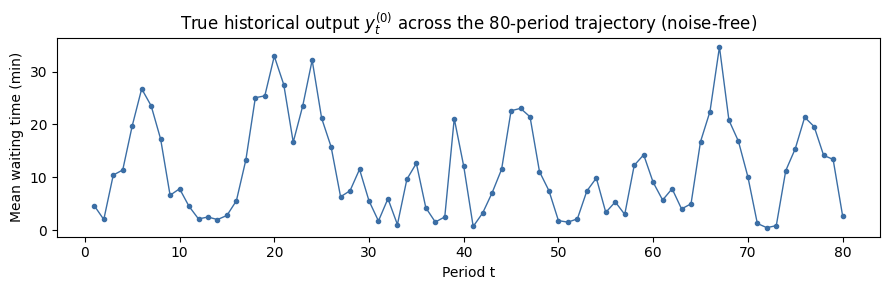

In [5]:
def generate_true_history(T, period_len, buffers, arr_rate, true_means, rng):
    psi_list, arrival_hist = [], []
    service_hist = [[] for _ in range(3)]
    y0 = []
    state = new_state()
    for t in range(T):
        psi_list.append(copy.deepcopy(state))  # snapshot BEFORE this period, i.e. psi_t
        state_in = restart_busy_events(copy.deepcopy(state), period_len)
        fb = {'S1': 0, 'S2': 0, 'S3': 0}
        new_st, deps, consumed = run_period(state_in, period_len, 'true', buffers, 'draw', arr_rate, None,
                                             ['draw'] * 3, true_means, (None, None, None), rng, fb)
        arrival_hist.append(consumed['arrival'])
        for j in range(3):
            service_hist[j].append(consumed['service'][j])
        y0.append(np.mean(deps) if deps else np.nan)
        state = new_st
    return psi_list, arrival_hist, service_hist, np.array(y0)


psi_list, arrival_hist, service_hist, y0 = generate_true_history(
    T_PERIODS, PERIOD_LEN, BUFFERS, ARRIVAL_RATE, TRUE_SERVICE_MEANS, rng)
y_obs = y0  # no noise added: the "observed" trajectory IS the true trajectory

print(f'y0: mean={np.nanmean(y0):.2f} min, std={np.nanstd(y0):.2f} min, '
      f'range=[{np.nanmin(y0):.2f}, {np.nanmax(y0):.2f}]')
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.arange(1, T_PERIODS + 1), y0, marker='o', ms=3, lw=1, color='#3b6ea5')
ax.set_xlabel('Period t'); ax.set_ylabel('Mean waiting time (min)')
ax.set_title('True historical output $y_t^{(0)}$ across the 80-period trajectory (noise-free)')
plt.tight_layout(); plt.show()


## 3. Candidate replication and the subtrace-conditional PIT ($\sigma_\varepsilon=0$ throughout)

Same functions as the original notebook; every call below passes `sigma_eps=0.0`.

In [6]:
def simulate_config_pit(bits, R, T, period_len, buffers, logic_mode, arr_rate, cand_means,
                         psi_list, arrival_hist, service_hist, y_obs, sigma_eps, rng):
    '''bits=(a,s1,s2,s3) in {0,1}: 1 = historical/fixed, 0 = simulated.
    Returns (U_hat[T], reps_matrix[T,R], fallback_totals).'''
    a_mode = 'replay' if bits[0] else 'draw'
    s_modes = ['replay' if bits[1 + j] else 'draw' for j in range(3)]
    U_hat = np.empty(T)
    reps_matrix = np.empty((T, R))
    fallback_totals = {'S1': 0, 'S2': 0, 'S3': 0}
    for t in range(T):
        reps = np.empty(R)
        for r in range(R):
            fb = {'S1': 0, 'S2': 0, 'S3': 0}
            st0 = restart_busy_events(copy.deepcopy(psi_list[t]), period_len)
            _, deps, _ = run_period(st0, period_len, logic_mode, buffers, a_mode, arr_rate, arrival_hist[t],
                                     s_modes, cand_means, [service_hist[j][t] for j in range(3)], rng, fb)
            base = np.mean(deps) if deps else 0.0
            reps[r] = base + rng.normal(0.0, sigma_eps)  # sigma_eps=0.0 everywhere in this notebook
            for k in fb:
                fallback_totals[k] += fb[k]
        reps_matrix[t] = reps
        U_hat[t] = np.mean(reps <= y_obs[t])
    return U_hat, reps_matrix, fallback_totals


def wasserstein_uniform(U):
    '''Closed-form W1 distance between the empirical distribution of the
    pooled PIT values U and Uniform(0,1).'''
    T = len(U)
    Uo = np.sort(U)
    grid = (2 * np.arange(1, T + 1) - 1) / (2 * T)
    return np.mean(np.abs(Uo - grid))


def simulate_null_pool(T, n_mc, rng):
    return np.array([wasserstein_uniform(rng.uniform(size=T)) for _ in range(n_mc)])


def holm_adjust(pvals):
    '''Holm's step-down FWER adjustment.'''
    pvals = np.asarray(pvals)
    m = len(pvals)
    order = np.argsort(pvals)
    adj = np.empty(m)
    running_max = 0.0
    for k, idx in enumerate(order):
        running_max = max(running_max, (m - k) * pvals[idx])
        adj[idx] = min(1.0, running_max)
    return adj


def bootstrap_W_from_reps(reps_matrix, y_obs, B, rng):
    '''Resample each period's R replicates with replacement (no new
    simulation), recompute the pooled Wasserstein statistic B times.'''
    T, R = reps_matrix.shape
    Ws = np.empty(B)
    for b in range(B):
        Ub = np.empty(T)
        for t in range(T):
            idx = rng.integers(0, R, size=R)
            Ub[t] = np.mean(reps_matrix[t, idx] <= y_obs[t])
        Ws[b] = wasserstein_uniform(Ub)
    return Ws


N_MC = 2000
Wnull_pool = simulate_null_pool(T_PERIODS, N_MC, rng)
print(f'Null W-statistic pool built from {N_MC} draws of {T_PERIODS} i.i.d. U(0,1) samples '
      f'(reused for every configuration/case below).')


Null W-statistic pool built from 2000 draws of 80 i.i.d. U(0,1) samples (reused for every configuration/case below).


## 4. The four cases

Identical definitions to the original notebook. `ALL_BITS` is the full
$2^4=16$ set of (Arrivals, S1, S2, S3) historical/simulated combinations.


In [7]:
CASES = {
    'Case 1: fully correct':    dict(cand_means=(1.0, 1.0, 2.0), logic='true'),
    'Case 2: input error only': dict(cand_means=(1.0, BAD_S2_MEAN, 2.0), logic='true'),
    'Case 3: logic error only': dict(cand_means=(1.0, 1.0, 2.0), logic='wrong'),
    'Case 4: both errors':      dict(cand_means=(1.0, BAD_S2_MEAN, 2.0), logic='wrong'),
}
ALL_BITS = list(itertools.product([0, 1], repeat=4))  # 16 configurations
FULL_TRACE_BITS = (1, 1, 1, 1)
REGULAR_BITS = [b for b in ALL_BITS if b != FULL_TRACE_BITS]  # the 15-row Holm family
print(f'{len(ALL_BITS)} configurations per case; {len(REGULAR_BITS)} regular + 1 special (full-trace) row.')


16 configurations per case; 15 regular + 1 special (full-trace) row.


## 5. Per-case no-noise tables

For each case, the 15 **regular** configurations (`REGULAR_BITS`, at least
one input simulated) are computed exactly as in the original notebook, just
with `sigma_eps=0.0`. Every table also carries an explicit **Logic** column
and is uniformly **16 rows**: the 15 regular rows plus exactly **one true
row** (every input *and* Logic Historical, $W_A:=0$). The 16th, full-trace
configuration is handled per the rule in the introduction:

- **Case 1, Case 2** (`logic='true'`): Logic = Historical throughout (this
  case never runs the wrong logic). The full-trace configuration reproduces
  $y_t^{(0)}$ exactly (proven reproduction; the naive formula's $0.5$ is an
  artifact of applying a continuous-distribution formula to a single
  point), so it *is* the table's true row, assigned $W_A:=0$ directly and
  excluded from the Holm family (it isn't a hypothesis test, it's a given).
- **Case 3, Case 4** (`logic='wrong'`): Logic = Simulated throughout (this
  case never runs the true logic), so none of its own 16 raw configurations
  is a true row. The table instead gets the same universal **true-system
  row** that is already the anchor in Cases 1-2 &mdash; reused directly
  from Case 1 rather than resimulated, since a full replay never touches
  the candidate model, so this fact does not depend on the case. The
  case's own full-trace configuration (all 4 inputs Historical under its
  own wrong logic, the **full-trace logic test**) is **not** a row in any
  table &mdash; it mixes all-Historical inputs with a different logic
  setting than every other row, so it doesn't belong in a table that only
  varies the four inputs. It is still computed (Sections 7-8 reuse it) and
  printed separately right under each of these two tables.

That way every one of the four tables contains exactly **one true row**
(Logic Historical, $W_A=0$), with every other row's Logic column reflecting
what was actually simulated for that case.


In [8]:
def build_case_table(case_name, params, rng):
    logic = params['logic']
    cand_means = params['cand_means']
    logic_label = 'Historical' if logic == 'true' else 'Simulated'

    reps_dict = {}
    regular_rows = []  # (bits, W, p_raw)
    for bits in REGULAR_BITS:
        U, reps, fb = simulate_config_pit(bits, R_REPS, T_PERIODS, PERIOD_LEN, BUFFERS, logic, ARRIVAL_RATE,
                                           cand_means, psi_list, arrival_hist, service_hist, y_obs, 0.0, rng)
        W = wasserstein_uniform(U)
        p = np.mean(Wnull_pool >= W)
        reps_dict[bits] = reps
        regular_rows.append((bits, W, p))

    p_holm = holm_adjust([r[2] for r in regular_rows])

    # The case's own full-trace value: exactly reproduces y0 (logic correct) or is the full-trace
    # logic test (logic wrong). Computed here because Sections 7-8 need it, but it is NEVER a row
    # in the table below -- it would mix all-Historical inputs with a DIFFERENT logic setting than
    # every other row in the table, which doesn't belong in a table whose columns are meant to vary
    # only the four inputs at a fixed logic.
    if logic == 'true':
        W_full = 0.0
        full_label = 'true system (anchor)'
        full_reps = None  # zero-variance by construction; handled specially in Section 7
    else:
        U_full, full_reps, _ = simulate_config_pit(FULL_TRACE_BITS, R_REPS, T_PERIODS, PERIOD_LEN, BUFFERS, logic,
                                                     ARRIVAL_RATE, cand_means, psi_list, arrival_hist, service_hist,
                                                     y_obs, 0.0, rng)
        W_full = wasserstein_uniform(U_full)
        full_label = 'logic test'

    recs = []
    for (bits, W, p), ph in zip(regular_rows, p_holm):
        recs.append({
            'Arrivals': 'Historical' if bits[0] else 'Simulated',
            'S1': 'Historical' if bits[1] else 'Simulated',
            'S2': 'Historical' if bits[2] else 'Simulated',
            'S3': 'Historical' if bits[3] else 'Simulated',
            'Logic': logic_label,
            'W_A': round(W, 4),
            'p_raw': round(p, 4),
            'p_holm': round(ph, 4),
            'Reject @0.05': bool(ph < 0.05),
        })
    if logic == 'true':
        # Here the case's own full-trace value already IS the true-system row (its logic is
        # already Historical), so it is added once, as that row.
        recs.append({
            'Arrivals': 'Historical', 'S1': 'Historical', 'S2': 'Historical', 'S3': 'Historical',
            'Logic': 'Historical',
            'W_A': round(W_full, 4), 'p_raw': np.nan, 'p_holm': '(true system)', 'Reject @0.05': None,
        })
    else:
        # The case's own logic is wrong, so its full-trace value is NOT a true-system row (it is
        # excluded above, reported separately). Add the one universal true-system row instead
        # (every input AND Logic Historical): a proven exact reproduction of y0, W:=0 by
        # construction (Section 1's sanity check). Reused directly, not resimulated -- a full
        # replay never calls the candidate model, so this fact holds regardless of the case.
        recs.append({
            'Arrivals': 'Historical', 'S1': 'Historical', 'S2': 'Historical', 'S3': 'Historical',
            'Logic': 'Historical',
            'W_A': 0.0, 'p_raw': np.nan, 'p_holm': '(true system)', 'Reject @0.05': None,
        })
    df = pd.DataFrame(recs).sort_values('W_A').reset_index(drop=True)
    return df, reps_dict, (W_full, full_label, full_reps)


case_tables = {}
case_reps = {}
case_full = {}
for case_name, params in CASES.items():
    df, reps_dict, full_info = build_case_table(case_name, params, rng)
    case_tables[case_name] = df
    case_reps[case_name] = reps_dict
    case_full[case_name] = full_info
    print(f'\n=== {case_name} ({len(df)} rows: 15 regular + 1 true-system row) ===')
    display(df)
    W_full, full_label, _ = full_info
    if full_label == 'logic test':
        print(f"(Not a row above -- reported separately, reused in Sections 7-8: {case_name}'s own "
              f'full-trace logic test, all 4 inputs Historical under its own wrong logic, '
              f'gives W_A = {W_full:.4f}.)')



=== Case 1: fully correct (16 rows: 15 regular + 1 true-system row) ===


,Arrivals,S1,S2,S3,Logic,W_A,p_raw,p_holm,Reject @0.05
0,Historical,Historical,Historical,Historical,Historical,0.0000,NaN,(true system),None
1,Historical,Historical,Simulated,Simulated,Historical,0.0203,0.8680,1.0,False
2,Historical,Simulated,Historical,Simulated,Historical,0.0209,0.8535,1.0,False
3,Historical,Simulated,Simulated,Simulated,Historical,0.0224,0.8100,1.0,False
4,Historical,Historical,Historical,Simulated,Historical,0.0264,0.6710,1.0,False
5,Simulated,Simulated,Simulated,Simulated,Historical,0.0268,0.6570,1.0,False
6,Simulated,Simulated,Historical,Simulated,Historical,0.0286,0.5885,1.0,False
7,Simulated,Historical,Historical,Simulated,Historical,0.0316,0.4975,1.0,False
8,Simulated,Historical,Simulated,Simulated,Historical,0.0348,0.4210,1.0,False
9,Historical,Simulated,Simulated,Historical,Historical,0.0382,0.3395,1.0,False



=== Case 2: input error only (16 rows: 15 regular + 1 true-system row) ===


,Arrivals,S1,S2,S3,Logic,W_A,p_raw,p_holm,Reject @0.05
0,Historical,Historical,Historical,Historical,Historical,0.0000,NaN,(true system),None
1,Historical,Simulated,Historical,Simulated,Historical,0.0236,0.7715,1.0,False
2,Historical,Historical,Historical,Simulated,Historical,0.0240,0.7605,1.0,False
3,Simulated,Simulated,Historical,Simulated,Historical,0.0321,0.4865,1.0,False
4,Simulated,Historical,Historical,Simulated,Historical,0.0335,0.4530,1.0,False
5,Simulated,Simulated,Historical,Historical,Historical,0.0614,0.0705,0.3525,False
6,Historical,Simulated,Historical,Historical,Historical,0.0704,0.0305,0.183,False
7,Simulated,Historical,Historical,Historical,Historical,0.0924,0.0040,0.028,True
8,Historical,Historical,Simulated,Simulated,Historical,0.2004,0.0000,0.0,True
9,Simulated,Simulated,Simulated,Simulated,Historical,0.2011,0.0000,0.0,True



=== Case 3: logic error only (16 rows: 15 regular + 1 true-system row) ===


,Arrivals,S1,S2,S3,Logic,W_A,p_raw,p_holm,Reject @0.05
0,Historical,Historical,Historical,Historical,Historical,0.0000,NaN,(true system),None
1,Simulated,Historical,Historical,Simulated,Simulated,0.1345,0.0,0.0,True
2,Simulated,Simulated,Historical,Simulated,Simulated,0.1378,0.0,0.0,True
3,Simulated,Simulated,Simulated,Simulated,Simulated,0.1385,0.0,0.0,True
4,Simulated,Historical,Simulated,Simulated,Simulated,0.1395,0.0,0.0,True
5,Historical,Simulated,Historical,Simulated,Simulated,0.1433,0.0,0.0,True
6,Historical,Historical,Simulated,Simulated,Simulated,0.1440,0.0,0.0,True
7,Historical,Simulated,Simulated,Simulated,Simulated,0.1458,0.0,0.0,True
8,Historical,Historical,Historical,Simulated,Simulated,0.1528,0.0,0.0,True
9,Simulated,Simulated,Simulated,Historical,Simulated,0.1761,0.0,0.0,True


(Not a row above -- reported separately, reused in Sections 7-8: Case 3: logic error only's own full-trace logic test, all 4 inputs Historical under its own wrong logic, gives W_A = 0.3556.)



=== Case 4: both errors (16 rows: 15 regular + 1 true-system row) ===


,Arrivals,S1,S2,S3,Logic,W_A,p_raw,p_holm,Reject @0.05
0,Historical,Historical,Historical,Historical,Historical,0.0000,NaN,(true system),None
1,Simulated,Simulated,Historical,Simulated,Simulated,0.1386,0.0,0.0,True
2,Simulated,Historical,Historical,Simulated,Simulated,0.1433,0.0,0.0,True
3,Historical,Historical,Historical,Simulated,Simulated,0.1468,0.0,0.0,True
4,Historical,Simulated,Historical,Simulated,Simulated,0.1482,0.0,0.0,True
5,Simulated,Simulated,Historical,Historical,Simulated,0.1918,0.0,0.0,True
6,Simulated,Historical,Historical,Historical,Simulated,0.1919,0.0,0.0,True
7,Simulated,Historical,Simulated,Simulated,Simulated,0.2043,0.0,0.0,True
8,Historical,Historical,Simulated,Simulated,Simulated,0.2045,0.0,0.0,True
9,Historical,Simulated,Simulated,Simulated,Simulated,0.2049,0.0,0.0,True


(Not a row above -- reported separately, reused in Sections 7-8: Case 4: both errors's own full-trace logic test, all 4 inputs Historical under its own wrong logic, gives W_A = 0.3556.)


# tasks. 
- build an importance based tree score for each dataset in previous case. 
- check the code to see if the code is written correctly and if the errors we enforce are enforced correctly. A way to check it is to check the importance scores from the treebased model. in any case that we enforce error, that source is expted to have a high scoeree. 


## 6. Tree-based importance scores per case (direct fit on the Section 5 tables)

For each case, fit a `DecisionTreeRegressor` directly on `case_tables[case_name]`
as it stands &mdash; no resampling, no bootstrap. Features are all **five**
columns (Arrivals, S1, S2, S3, Logic, each Historical=1/Simulated=0), target
is `W_A`. With only 16 rows the tree grows fully and can isolate every point
into its own leaf, so this isn't a generalization claim; it's a diagnostic
of which factor's splits account for the discrepancy in *this* table &mdash;
enough to answer the validation question below.



=== Case 1: fully correct: tree-based importance (direct fit on the 16-row table) ===


,process,importance
0,S3,0.358404
1,S2,0.355983
2,Arrivals,0.158743
3,S1,0.126870
4,Logic,0.000000



=== Case 2: input error only: tree-based importance (direct fit on the 16-row table) ===


,process,importance
0,S2,0.942826
1,S1,0.025613
2,S3,0.015803
3,Arrivals,0.015758
4,Logic,0.000000



=== Case 3: logic error only: tree-based importance (direct fit on the 16-row table) ===


,process,importance
0,Logic,0.695126
1,S3,0.263880
2,S2,0.021495
3,Arrivals,0.018811
4,S1,0.000688



=== Case 4: both errors: tree-based importance (direct fit on the 16-row table) ===


,process,importance
0,Logic,0.735031
1,S2,0.132147
2,S3,0.120908
3,Arrivals,0.011524
4,S1,0.000390


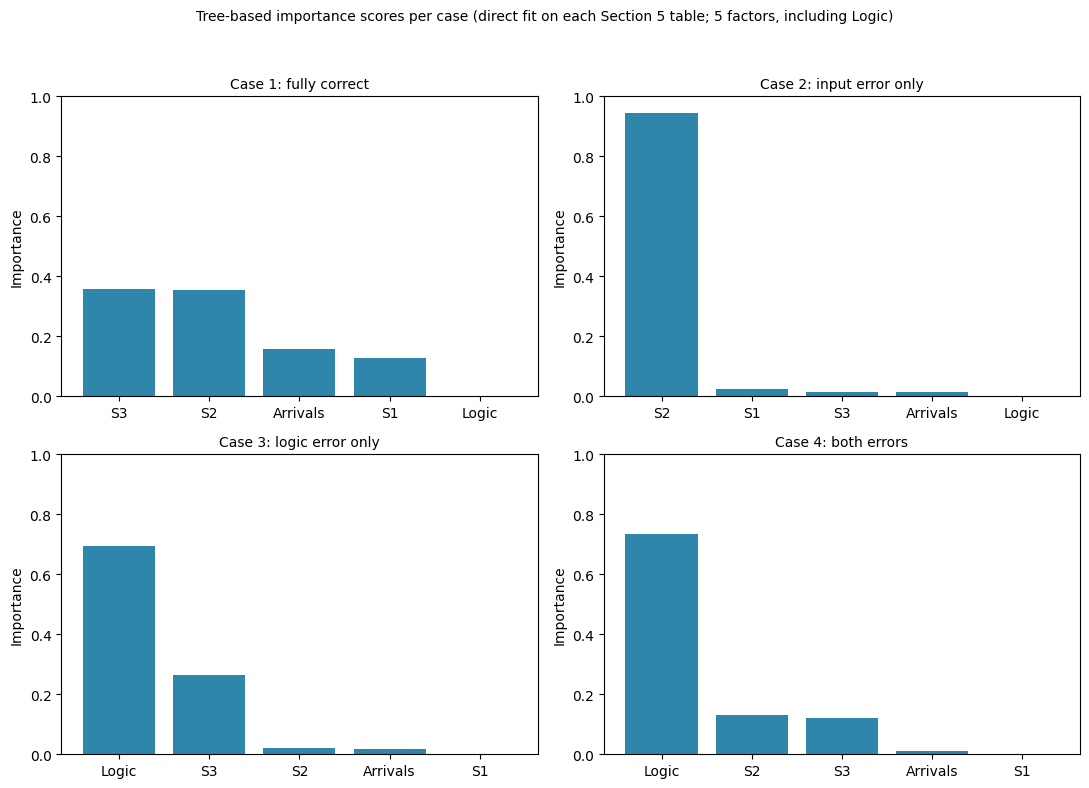

In [9]:
FEATURE_COLS = ['Arrivals', 'S1', 'S2', 'S3', 'Logic']

case_tree_importances = {}
for case_name in CASES:
    df = case_tables[case_name]
    X = np.array([[1 if df.loc[i, c] == 'Historical' else 0 for c in FEATURE_COLS] for i in df.index])
    y = df['W_A'].to_numpy()

    tree = DecisionTreeRegressor(random_state=SEED)  # fully grown: only 16 rows
    tree.fit(X, y)
    imp = pd.DataFrame({'process': FEATURE_COLS, 'importance': tree.feature_importances_}) \
        .sort_values('importance', ascending=False).reset_index(drop=True)
    case_tree_importances[case_name] = imp

    print(f'\n=== {case_name}: tree-based importance (direct fit on the {len(df)}-row table) ===')
    display(imp)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, case_name in zip(axes.flat, CASES):
    imp = case_tree_importances[case_name]
    ax.bar(imp['process'], imp['importance'], color='#2e86ab')
    ax.set_ylim(0, 1)
    ax.set_ylabel('Importance')
    ax.set_title(case_name, fontsize=10)
fig.suptitle('Tree-based importance scores per case (direct fit on each Section 5 table; '
             '5 factors, including Logic)', fontsize=10)
plt.tight_layout(rect=[0, 0, 1, 0.95]); plt.show()


### 6.1 Validation: does each case's enforced error show up as high importance?

This is the code-correctness check requested above: in any case where an
error was deliberately enforced, that error's source should come out with a
high importance score. If it doesn't, that's a sign the error injection
(or the table/PIT construction) isn't doing what it's supposed to.

- **Case 1** (`cand_means` = truth, `logic='true'`): no error enforced, so
  no factor should dominate &mdash; whatever comes out "on top" is just the
  small amount of structure left in 15 stochastic rows plus one exact zero,
  not a real signal.
- **Case 2** (bad S2 mean, correct logic): **S2** should dominate.
- **Case 3** (correct means, wrong logic): **Logic** should dominate.
- **Case 4** (bad S2 mean *and* wrong logic): **S2** and **Logic** should be
  the top two.


In [10]:
EXPECTED_SOURCE = {
    'Case 1: fully correct':    [],
    'Case 2: input error only': ['S2'],
    'Case 3: logic error only': ['Logic'],
    'Case 4: both errors':      ['S2', 'Logic'],
}

print('Validation check: for each case, does the tree rank the deliberately-injected '
      'error source(s) highest?\n')
for case_name in CASES:
    ranked = case_tree_importances[case_name].set_index('process')['importance'].sort_values(ascending=False)
    expected = EXPECTED_SOURCE[case_name]

    print(f'{case_name}:')
    print(f'  ranked importances: {dict(ranked.round(3))}')
    if not expected:
        top = ranked.index[0]
        print(f'  (no error enforced) top factor is "{top}" at {ranked.iloc[0]:.3f} -- '
              f'expected to be unremarkable, not a dominant signal.\n')
    else:
        k = len(expected)
        top_k = set(ranked.index[:k])
        if top_k == set(expected):
            print(f'  PASS: expected source(s) {expected} occupy the top {k} importance slot(s).\n')
        else:
            print(f'  FAIL: expected {expected} to dominate, but the top {k} slot(s) are '
                  f'{list(ranked.index[:k])} instead. Check the error-injection code for this case.\n')


Validation check: for each case, does the tree rank the deliberately-injected error source(s) highest?

Case 1: fully correct:
  ranked importances: {'S3': np.float64(0.358), 'S2': np.float64(0.356), 'Arrivals': np.float64(0.159), 'S1': np.float64(0.127), 'Logic': np.float64(0.0)}
  (no error enforced) top factor is "S3" at 0.358 -- expected to be unremarkable, not a dominant signal.

Case 2: input error only:
  ranked importances: {'S2': np.float64(0.943), 'S1': np.float64(0.026), 'S3': np.float64(0.016), 'Arrivals': np.float64(0.016), 'Logic': np.float64(0.0)}
  PASS: expected source(s) ['S2'] occupy the top 1 importance slot(s).

Case 3: logic error only:
  ranked importances: {'Logic': np.float64(0.695), 'S3': np.float64(0.264), 'S2': np.float64(0.021), 'Arrivals': np.float64(0.019), 'S1': np.float64(0.001)}
  PASS: expected source(s) ['Logic'] occupy the top 1 importance slot(s).

Case 4: both errors:
  ranked importances: {'Logic': np.float64(0.735), 'S2': np.float64(0.132), 'S3'